In [2]:
import pandas as pd
import matplotlib.pyplot as plt

### Inventory_Turnover Analysis

In [3]:
inventory_df = pd.read_csv("Inventory_Turnover.csv")

In [4]:
# convert to datetime dtype
inventory_df['dispense_date'] = pd.to_datetime(inventory_df['dispense_date'], dayfirst=True, format='mixed')#, format='ISO8601') #

In [5]:
# add time-based attributes, month and year fields
inventory_df['dispense_month'] = inventory_df['dispense_date'].dt.to_period('M')
inventory_df['dispense_year'] = inventory_df['dispense_date'].dt.to_period('Y')

In [6]:
inventory_df.info()

# inventory_df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38982 entries, 0 to 38981
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   sku             38982 non-null  object        
 1   dispense_date   38982 non-null  datetime64[ns]
 2   device_id       38982 non-null  object        
 3   package_qty     38982 non-null  int64         
 4   qty_dispensed   38982 non-null  int64         
 5   dispense_month  38982 non-null  period[M]     
 6   dispense_year   38982 non-null  period[Y-DEC] 
dtypes: datetime64[ns](1), int64(2), object(2), period[M](1), period[Y-DEC](1)
memory usage: 2.1+ MB


In [7]:
inventory_df#.head(20)

,sku,dispense_date,device_id,package_qty,qty_dispensed,dispense_month,dispense_year
0,05d98e5c2603bf927952aa3eb74d1fc3,2024-02-22,device_0749c361d8ac7047c2f98fbcb2eadd16,1,20,2024-02,2024
1,05d98e5c2603bf927952aa3eb74d1fc3,2024-02-21,device_0749c361d8ac7047c2f98fbcb2eadd16,1,9,2024-02,2024
2,05d98e5c2603bf927952aa3eb74d1fc3,2024-02-20,device_0749c361d8ac7047c2f98fbcb2eadd16,1,15,2024-02,2024
3,05d98e5c2603bf927952aa3eb74d1fc3,2024-02-19,device_0749c361d8ac7047c2f98fbcb2eadd16,1,13,2024-02,2024
4,05d98e5c2603bf927952aa3eb74d1fc3,2024-02-18,device_0749c361d8ac7047c2f98fbcb2eadd16,1,24,2024-02,2024
...,...,...,...,...,...,...,...
38977,f25382528bbc59704a0f32b0f929a532,2022-03-23,device_c287be7e02167387bf9e7eca061ce5b5,1,1,2022-03,2022
38978,f25382528bbc59704a0f32b0f929a532,2022-03-18,device_c287be7e02167387bf9e7eca061ce5b5,1,1,2022-03,2022
38979,f25382528bbc59704a0f32b0f929a532,2022-03-16,device_c287be7e02167387bf9e7eca061ce5b5,1,1,2022-03,2022
38980,f25382528bbc59704a0f32b0f929a532,2022-03-06,device_c287be7e02167387bf9e7eca061ce5b5,1,1,2022-03,2022


In [8]:
# show month frequency
# inventory_df['dispense_month'].value_counts().sort_index()

# show day frequency
inventory_df['dispense_date'].value_counts().sort_index()

dispense_date
2022-02-23    55
2022-02-24    59
2022-02-25    58
2022-02-26    59
2022-02-27    61
              ..
2024-02-19    52
2024-02-20    48
2024-02-21    46
2024-02-22    54
2024-02-23    17
Name: count, Length: 728, dtype: int64

In [9]:
# show year frequency
inventory_df['dispense_year'].value_counts().sort_index()

dispense_year
2022    17666
2023    18667
2024     2649
Freq: Y-DEC, Name: count, dtype: int64

In [10]:
inventory_df['device_id'] = inventory_df['device_id'].replace(
                                   {'device_65ae7ea424c57d46ac409256fe359349': 'A',
                                   'device_6726f2a054f54836aaabe8c7643286bc': 'B',
                                   'device_c287be7e02167387bf9e7eca061ce5b5': 'C',
                                   'device_0749c361d8ac7047c2f98fbcb2eadd16': 'D',
                                   'device_af645ebf4c96eb6e430529a2a9913686': 'E'})

inventory_df['device_id'].unique()
inventory_df['sku'].value_counts()

sku
690b7d2f4218991b6496be8eb456a943    726
9a154810b166b91ae0c3d0cd84fb7e05    725
05d98e5c2603bf927952aa3eb74d1fc3    724
69c93e0ed056c1f8056e644a63612ea1    724
5fd43334dbbeb041fc1f6be0ce5c40f6    723
                                   ... 
a0b58e14d2d6c95d5c9e8ebb4db73e50     39
160173e79ddfe9508c02f8cdb93daff9     17
48d1f3625ed89240b0c15486880eb40a     15
924aa4fc983c1f8364e5bd1f04cbb062      2
461104747ec72f92b0faf4da6d904934      2
Name: count, Length: 82, dtype: int64

In [11]:
# segment inventory by year
inventory2022_df = inventory_df[inventory_df['dispense_date'].dt.year == 2022]
inventory2023_df = inventory_df[inventory_df['dispense_date'].dt.year == 2023]
inventory2024_df = inventory_df[inventory_df['dispense_date'].dt.year == 2024]

# len(inventory2024_df)
# inventory2024_df['dispense_date'].dt.dayofweek.value_counts()

In [12]:
# show total quantity dispensed per month by all vending machines
inv_2022_df = inventory2022_df.groupby('dispense_month').agg(total_qty_dispensed=('qty_dispensed', 'sum')).reset_index()
inv_2022_df = inv_2022_df[['dispense_month', 'total_qty_dispensed']]
inv_2022_df.index = inv_2022_df['dispense_month']
inv_2022_df.index = inv_2022_df.index.to_timestamp()
del inv_2022_df['dispense_month']

inv_2023_df = inventory2023_df.groupby('dispense_month').agg(total_qty_dispensed=('qty_dispensed', 'sum')).reset_index()
inv_2023_df = inv_2023_df[['dispense_month', 'total_qty_dispensed']]
inv_2023_df.index = inv_2023_df['dispense_month']
inv_2023_df.index = inv_2023_df.index.to_timestamp()
del inv_2023_df['dispense_month']

inv_2024_df = inventory2024_df.groupby('dispense_month').agg(total_qty_dispensed=('qty_dispensed', 'sum')).reset_index()
inv_2024_df = inv_2024_df[['dispense_month', 'total_qty_dispensed']]
inv_2024_df.index = inv_2024_df['dispense_month']
inv_2024_df.index = inv_2024_df.index.to_timestamp()
del inv_2024_df['dispense_month']

inv_2022_df.info()
inv_2023_df.info()
inv_2024_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 11 entries, 2022-02-01 to 2022-12-01
Freq: MS
Data columns (total 1 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   total_qty_dispensed  11 non-null     int64
dtypes: int64(1)
memory usage: 176.0 bytes
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 12 entries, 2023-01-01 to 2023-12-01
Freq: MS
Data columns (total 1 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   total_qty_dispensed  12 non-null     int64
dtypes: int64(1)
memory usage: 192.0 bytes
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2 entries, 2024-01-01 to 2024-02-01
Data columns (total 1 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   total_qty_dispensed  2 non-null      int64
dtypes: int64(1)
memory usage: 32.0 bytes


In [13]:
import plotly.express as px

df = pd.concat([inv_2022_df, inv_2023_df, inv_2024_df])
fig = px.line(
    df,
    x=df.index,
    y="total_qty_dispensed",
    markers=True
)
# fig.update_xaxes(type="category")   # force categorical axis
fig.update_layout(title="Quantity Dispensed Per Month by all vending machines\n(Feb 2022 - Feb 2024)")
fig.show()


In [14]:
# Dataframes of Total Quantity Dispensed Per Month by each vending machine
vminv_2022_df = inventory2022_df.groupby(['dispense_month', 'device_id']).agg(total_qty_dispensed=('qty_dispensed', 'sum')).reset_index()
vminv_2022_df = vminv_2022_df[['dispense_month', 'device_id', 'total_qty_dispensed']]
vminv_2022_df.index = vminv_2022_df['dispense_month']
vminv_2022_df.index = vminv_2022_df.index.to_timestamp()
del vminv_2022_df['dispense_month']

vminv_2023_df = inventory2023_df.groupby(['dispense_month', 'device_id']).agg(total_qty_dispensed=('qty_dispensed', 'sum')).reset_index()
vminv_2023_df = vminv_2023_df[['dispense_month', 'device_id', 'total_qty_dispensed']]
vminv_2023_df.index = vminv_2023_df['dispense_month']
vminv_2023_df.index = vminv_2023_df.index.to_timestamp()
del vminv_2023_df['dispense_month']

vminv_2024_df = inventory2024_df.groupby(['dispense_month', 'device_id']).agg(total_qty_dispensed=('qty_dispensed', 'sum')).reset_index()
vminv_2024_df = vminv_2024_df[['dispense_month', 'device_id', 'total_qty_dispensed']]
vminv_2024_df.index = vminv_2024_df['dispense_month']
vminv_2024_df.index = vminv_2024_df.index.to_timestamp()
del vminv_2024_df['dispense_month']

vminv_2022_df.info()
vminv_2023_df.info()
vminv_2024_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 55 entries, 2022-02-01 to 2022-12-01
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   device_id            55 non-null     object
 1   total_qty_dispensed  55 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.3+ KB
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 60 entries, 2023-01-01 to 2023-12-01
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   device_id            60 non-null     object
 1   total_qty_dispensed  60 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.4+ KB
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 10 entries, 2024-01-01 to 2024-02-01
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   device_id            10 non-null     ob

In [15]:
# Line plot of Total Quantity Dispensed Per Month by each vending machine
import plotly.express as px

df = pd.concat([vminv_2022_df, vminv_2023_df, vminv_2024_df])
fig = px.line(
    df,
    x=df.index,
    y="total_qty_dispensed",
    color="device_id",
    markers=True
)
fig.update_layout(title="Quantity Dispensed Per Month by each vending machine\n(Feb 2022 - Feb 2024)",
                  legend_title_text="Vending Machine")
fig.show()


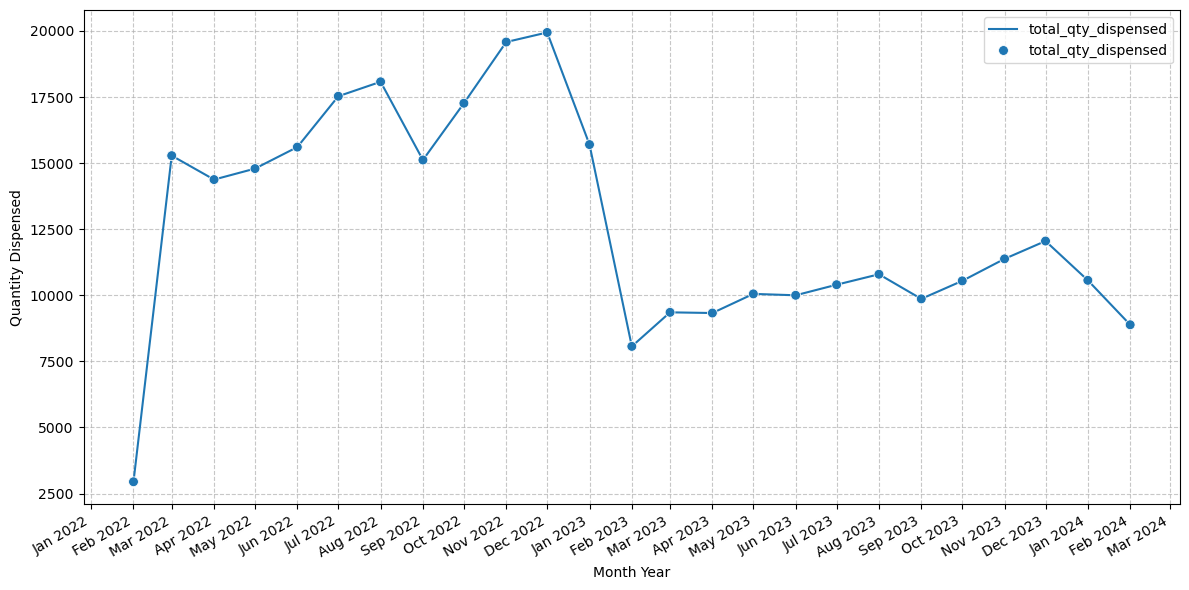

In [16]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns 
# import mplcursors

plt.close()   # clears the current figure

# Set a wider figure size
plt.figure(figsize=(12, 6))  # width=12 inches, height=6 inches

df = pd.concat([inv_2022_df, inv_2023_df, inv_2024_df])
sns.lineplot(data=df)

# Overlay datapoints
# points = 
sns.scatterplot(data=df, s=50, color="red", zorder=5)

plt.xlabel('Month Year')
plt.ylabel('Quantity Dispensed')
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
# plt.xticks(rotation=45)  # Rotate labels 45 degrees
plt.setp(plt.gca().get_xticklabels(), rotation=30, ha="right")

plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

### Augmented Dickey-Fuller (ADF) Test

In [17]:
from statsmodels.tsa.stattools import adfuller

df = pd.concat([inv_2022_df, inv_2023_df, inv_2024_df])
adft = adfuller(df, autolag="AIC")

output_df = pd.DataFrame({"Values":[adft[0],adft[1],adft[2],adft[3], adft[4]['1%'], adft[4]['5%'], adft[4]['10%']]  , "Metric":["Test Statistics","p-value","No. of lags used","Number of observations used", 
                                                        "critical value (1%)", "critical value (5%)", "critical value (10%)"]})
output_df

,Values,Metric
0,-1.448566,Test Statistics
1,0.558784,p-value
2,1.000000,No. of lags used
3,23.000000,Number of observations used
4,-3.752928,critical value (1%)
5,-2.998500,critical value (5%)
6,-2.638967,critical value (10%)


The ADF test uses two hypotheses:
<table>
    <tr>
    <th>Hypothesis</th>
    <th>Meaning</th>
    </tr>
    <tr>
    <td>H₀ (Null hypothesis)</td>
    <td>The time series has a unit root (non-stationary).</td>
    </tr>
    <tr>
    <td>H₁ (Alternative hypothesis)</td>
    <td>The time series does not have a unit root (stationary).</td>
    </tr>
</table>  

The important distinction is:
- If p-value is less than 0.05, reject H₀. Evidence supports stationarity.
- If p-value is greater than 0.05, fail to reject H₀. Insufficient evidence to conclude stationarity.

Reference: [1. Understanding the ADF test](https://chatgpt.com/s/t_6af014d8dd1c8191a2fe043705f47c3b)

Interpreting the important values:

A. p-value = 0.558784  
Since p-value > 0.05, we fail to reject the null hypothesis.  
There is insufficient statistical evidence to conclude that the dispensing time series is stationary.

B. Test statistic = -1.448566  
Since T-Statistic is not more negative or lower than the critical values, we fail to reject the null hypothesis.

**Conclusion: The original dispensing series is non-stationary according to the ADF test.**

Reference: [2. Interpreting your actual results](https://chatgpt.com/s/t_6af014d8dd1c8191a2fe043705f47c3b)

### Autocorrelation

In [18]:
df = pd.concat([inv_2022_df, inv_2023_df, inv_2024_df])

lag1 = df['total_qty_dispensed'].autocorr(lag=1)
print("One Month Lag: ", lag1)
lag3 = df['total_qty_dispensed'].autocorr(lag=3)
print("Three Month Lag: ", lag3)
lag6 = df['total_qty_dispensed'].autocorr(lag=6)
print("Six Month Lag: ", lag6)
lag9 = df['total_qty_dispensed'].autocorr(lag=9)
print("Nine Month Lag: ", lag9)
lag12 = df['total_qty_dispensed'].autocorr(lag=12)
print("Twelve Month Lag: ", lag12)

One Month Lag:  0.6301551867317233
Three Month Lag:  0.2839972071961777
Six Month Lag:  -0.11515266092323856
Nine Month Lag:  -0.4122683797304699
Twelve Month Lag:  0.8982757978214098


Three observations stand out:
1. There is moderate short-term dependence (lag 1).
2. There is little correlation at six months.
3. There is a very strong relationship at twelve months.

This suggests that annual seasonality may exist, but we need to investigate whether it is stable enough to use for forecasting.

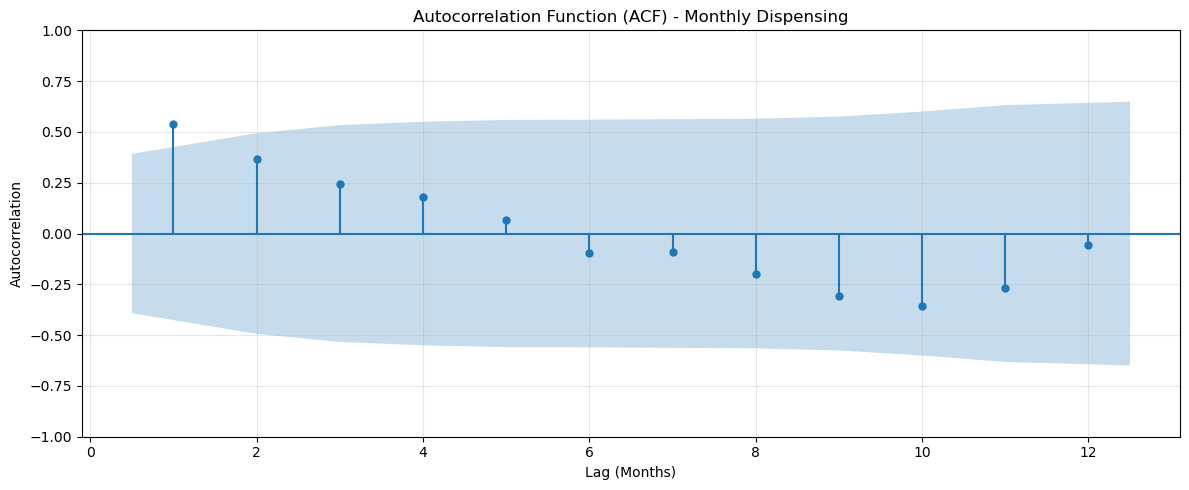

In [19]:
# visualize autocorrelation with ACF plot
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

fig, ax = plt.subplots(figsize=(12, 5))

plot_acf(
    df['total_qty_dispensed'],
    lags=12,
    ax=ax,
    zero=False
)

ax.set_title(
    'Autocorrelation Function (ACF) - Monthly Dispensing'
)

ax.set_xlabel('Lag (Months)')
ax.set_ylabel('Autocorrelation')

ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

The ACF plot includes confidence bands. Correlations extending beyond those bands are potential evidence of statistically significant autocorrelation, subject to the assumptions behind the confidence intervals.

Reference: [4. How to visualize autocorrelation](https://chatgpt.com/s/t_6af00f6734f081918ebcf3a5ea31de23)

In [20]:
# Compare monthly observations with their values
# from 12 months earlier.

seasonal_comparison = pd.DataFrame({
    'Current_Qty': df['total_qty_dispensed'],
    'Previous_Year_Qty': df['total_qty_dispensed'].shift(12)
})

seasonal_comparison['Difference'] = (
    seasonal_comparison['Current_Qty']
    - seasonal_comparison['Previous_Year_Qty']
)

seasonal_comparison['Percentage_Change'] = (
    seasonal_comparison['Difference']
    / seasonal_comparison['Previous_Year_Qty']
    * 100
)

print(seasonal_comparison.dropna().round(2))

                Current_Qty  Previous_Year_Qty  Difference  Percentage_Change
dispense_month                                                               
2023-02-01             8068             2947.0      5121.0             173.77
2023-03-01             9356            15283.0     -5927.0             -38.78
2023-04-01             9330            14378.0     -5048.0             -35.11
2023-05-01            10054            14793.0     -4739.0             -32.04
2023-06-01            10001            15607.0     -5606.0             -35.92
2023-07-01            10401            17530.0     -7129.0             -40.67
2023-08-01            10796            18077.0     -7281.0             -40.28
2023-09-01             9865            15119.0     -5254.0             -34.75
2023-10-01            10546            17266.0     -6720.0             -38.92
2023-11-01            11379            19581.0     -8202.0             -41.89
2023-12-01            12053            19943.0     -7890.0      

The same-month quantities are not close in magnitude, they simply move in a similar direction.

### Decomposition

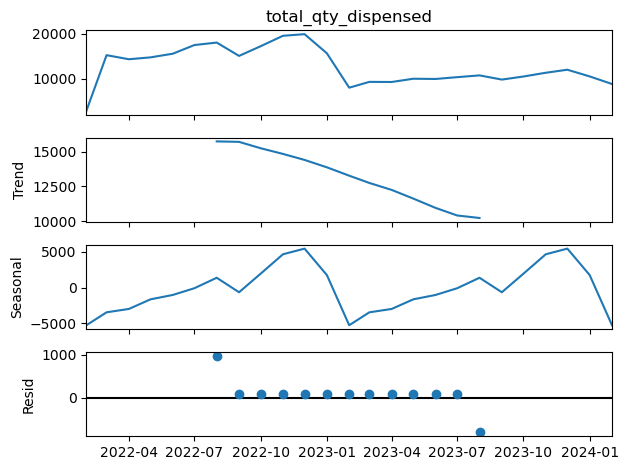

In [21]:
from statsmodels.tsa.seasonal import seasonal_decompose

df = pd.concat([inv_2022_df, inv_2023_df, inv_2024_df])
additive = seasonal_decompose(df['total_qty_dispensed'],model='additive',period=12)
fig = additive.plot()
plt.show()

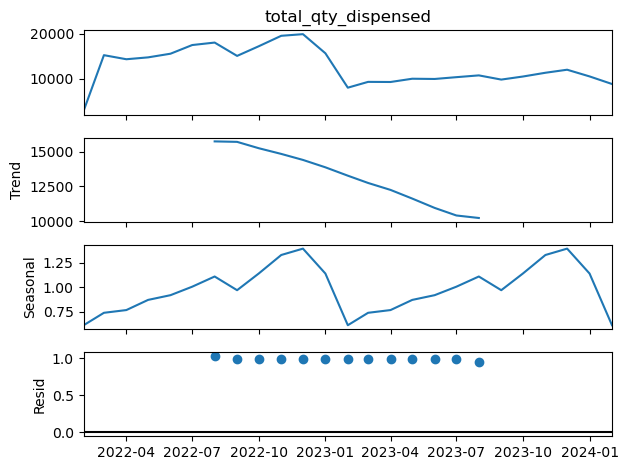

In [22]:
multiplicative = seasonal_decompose(df['total_qty_dispensed'],model='multiplicative',period=12)
fig = multiplicative.plot()
plt.show()

The time-series decomposition indicates a clear downward trend in total quantity dispensed from late 2022 through 2023. There is also evidence of annual seasonality, with dispensing generally higher toward November–December and lower around February–March. The residual component is relatively small for most months, although there are notable deviations around August 2022 and August 2023. An additive decomposition is reasonable if these seasonal changes represent relatively constant changes in units; a multiplicative decomposition would be more appropriate if seasonal fluctuations scale proportionally with the overall demand level.

Reference: [12. The big picture](https://chatgpt.com/s/t_6aeec1ba0f9081919ea11aa3ca9c1961)

### Summary Statistics

In [27]:
import numpy as np

inventory_df.describe(exclude=['number', 'datetime64[ns]'])

,sku,device_id,dispense_month,dispense_year
count,38982,38982,38982,38982
unique,82,5,25,3
top,690b7d2f4218991b6496be8eb456a943,E,2022-07,2023
freq,726,9036,1821,18667


count: all columns have data in all records  
unique: the counts (82, 5, 25, 3) give some perspective  
top: the most common value  
freq: the counts of the most common values (top) give little perspective, the qty_dispensed is what matters

In [26]:
inventory_df.describe(include=['number', 'datetime64[ns]'])

,dispense_date,package_qty,qty_dispensed
count,38982,38982.000000,38982.000000
mean,2023-02-13 00:21:18.867169536,1.000487,8.145503
min,2022-02-23 00:00:00,1.000000,1.000000
25%,2022-08-12 00:00:00,1.000000,2.000000
50%,2023-02-04 00:00:00,1.000000,5.000000
75%,2023-08-18 00:00:00,1.000000,12.000000
max,2024-02-23 00:00:00,2.000000,162.000000
std,NaN,0.022072,9.055199


count: all columns have data in all records  
mean, min, 25%, 50%, 75%, max, std: these stats give little perspective, the qty_dispensed trend is what matters